In [1]:
import pandas as pd
import numpy as np
from src.data.metrics import get_metrics, exclude_tuning_samples
from src.data.utils import load_data, get_trajectories, get_discretization

import matplotlib.ticker as mtick

import matplotlib.pyplot as plt

In [2]:
N_TUNE_800 = 8839
N_TUNE_400 = 5000

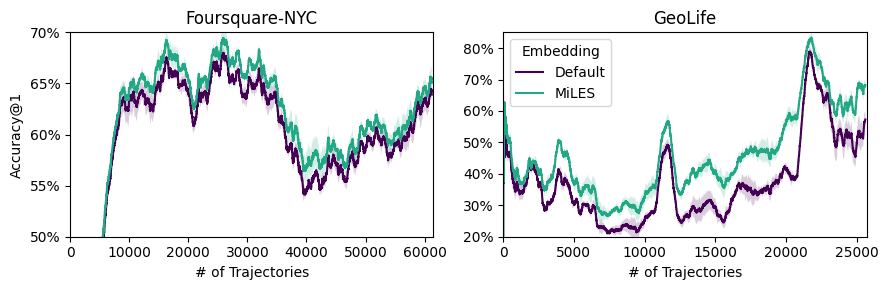

In [3]:
df = pd.read_json("../reports/TUL.jsonl", lines=True, orient="records")
df["replay_buffer_type"] = df["replay_buffer_type"].fillna("none")

# Embedding Methods
df = df[
    (df["replay_buffer_type"] == "none") & (df["optimizer_cls"] == "Adam")
]
emb_names = {
    "lookup_sum": "Lookup",
    "lookup_concat": "Lookup",
    "lookup_weighted_concat": "MiLES",
    "fourier": "Fourier",
    "linear": "Linear",
}
df.loc[:, "embedding_type"]= df.loc[:, "embedding_type"].apply(emb_names.get)
df = df[df['embedding_type'].isin(["Lookup", "MiLES"])]


metrics = ["top_1_accuracy", "top_5_accuracy", "macro_f1"]

exclude_tuning_samples(df)

df = df[df['n_users'].isin([150, 800])]
datasets = [
    ("foursquare_NYC", "Foursquare-NYC"),
    ("geolife", "GeoLife"),
]

fig, axs = plt.subplots(ncols=2, figsize=(9, 3), sharey=False)

cmap = plt.get_cmap("viridis", 6)
colors = (cmap(0), cmap(3))

for ax, (dataset_key, dataset_label) in zip(axs, datasets):
    dfp = df[(df['dataset'] == dataset_key) & (df['model_cls'] == "BiTULER")]
    window = 5000 if dataset_key == "foursquare_NYC" else 1000
    for idx, (emb, df_emb) in enumerate(dfp.groupby("embedding_type")):
        rolling_top1_per_seed = []

        for seed, df_seed in df_emb.groupby("seed"):
            labels = np.array(df_seed["labels"].item())
            preds = np.array(df_seed["preds"].item())

            top1 =(labels == preds).astype(float)
            rolling_top1 = pd.Series(top1).rolling(
                window=window, min_periods=1
            ).mean()
            rolling_top1_per_seed.append(rolling_top1.values)

        rolling_top1 = np.vstack(rolling_top1_per_seed) * 100
        rolling_top1_mean = np.mean(rolling_top1, axis=0)
        rolling_top1_std = np.std(rolling_top1, axis=0) * 4

        label = "Default" if emb == "Lookup" else "MiLES"
        x = np.arange(len(rolling_top1_mean))

        ax.plot(rolling_top1_mean, color=colors[idx], label=label)
        ax.fill_between(
            x,
            rolling_top1_mean - rolling_top1_std,
            rolling_top1_mean + rolling_top1_std,
            color=colors[idx],
            alpha=0.2,
            ec=None
        )

    ax.set_title(dataset_label)
    ax.set_xlabel("# of Trajectories")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

axs[0].set_ylabel("Accuracy@1")
axs[-1].legend(title="Embedding")

axs[0].set_ylim(50, 70)
axs[1].set_ylim(20, 85)

axs[0].set_xlim(0, 61500)
axs[1].set_xlim(0, 25700)

plt.tight_layout()
fig.savefig("../pub/figs/performance_over_time.png", bbox_inches="tight", dpi=300)

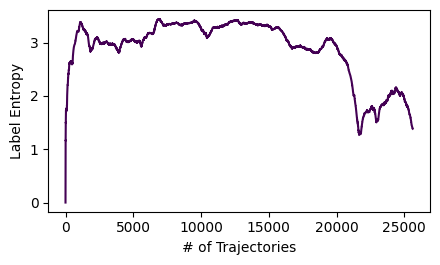

In [84]:
from scipy.stats import entropy
datasets = [
    ("foursquare_NYC", "Foursquare-NYC"),
    ("geolife", "GeoLife"),
]
window = 1000

fig, ax = plt.subplots(ncols=1, figsize=(4.5, 2.75), sharey=False)

cmap = plt.get_cmap("viridis", 6)
colors = (cmap(0), cmap(0))

# for ax, (dataset_key, dataset_label) in zip(axs, datasets):
dfp = df[
    (df["dataset"] == "geolife")
    & (df["model_cls"] == "BiTULER")
    & (df["seed"] == 0)
    & (df['embedding_type'] == "MiLES")
]
labels = np.array(dfp["labels"].item())
rolling_entropy = []
for i in range(len(labels)):
    start = max(0, i - window)
    window_labels = labels[start:i+1]
    _, counts = np.unique(window_labels, return_counts=True)
    rolling_entropy.append(entropy(counts))

rolling_entropy = np.array(rolling_entropy)

ax.plot(rolling_entropy, color=colors[idx], label=label)

# ax.set_title(dataset_label)
ax.set_xlabel("# of Trajectories")
# ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

ax.set_ylabel("Label Entropy")

# axs[0].set_ylim(50, 95)

plt.tight_layout()

fig.savefig("../pub/figs/label_entropy_geolife.pdf", bbox_inches="tight")

In [ ]:
from scipy.special import kl_div
dataset = 'foursquare_NYC'
n_users = 800
discretization_rows=400
discretization_shape='hex'

df, x_features, t_features, _ = load_data(
    dataset=dataset,
    n_users=n_users,
)
df_quantized = get_discretization(
    df,
    n_rows=discretization_rows,
)
n_locs = [df_quantized[x_feature].nunique() + 1 for x_feature in x_features]
n_times = [df_quantized[t_feature].nunique() + 1 for t_feature in t_features[:-1]]
trajectories = get_trajectories(
    df=df_quantized,
    x_features=x_features,
    t_features=t_features,
)
x, t, ll, u = zip(*trajectories)
x0 = [xi[:, 0] for xi in x]


def tumbling_window_kl(poi_sequences, n_pois, window_size=5000):
    """KL divergence between consecutive tumbling windows of trajectories."""
    n_trajs = len(poi_sequences)
    n_windows = n_trajs // window_size

    eps = 1e-10
    kl_values = []
    positions = []

    for w in range(1, n_windows):
        prev_pois = np.concatenate(
            poi_sequences[window_size * (w - 1) : window_size * w]
        )
        curr_pois = np.concatenate(
            poi_sequences[window_size * w : window_size * (w + 1)]
        )

        p = np.bincount(prev_pois, minlength=n_pois).astype(float)
        q = np.bincount(curr_pois, minlength=n_pois).astype(float)

        p = p / p.sum() + eps
        q = q / q.sum() + eps
        p /= p.sum()
        q /= q.sum()

        kl_values.append(np.sum(kl_div(p, q)))
        positions.append(window_size * w)

    return positions, kl_values

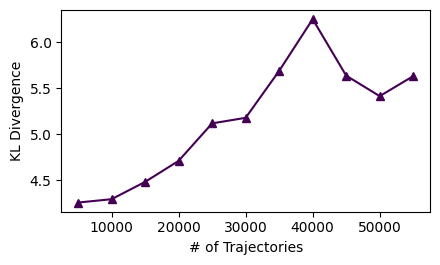

In [85]:
fig, ax = plt.subplots(ncols=1, figsize=(4.5, 2.75), sharey=False)

cmap = plt.get_cmap("viridis", 6)
color = cmap(0)

positions, kl_values = tumbling_window_kl(x0, n_pois=34383, window_size=5000)
ax.plot(positions, kl_values, color=color, marker='^')
ax.set_xlabel("# of Trajectories")
ax.set_ylabel("KL Divergence")
plt.tight_layout()

fig.savefig("../pub/figs/kl_divergence_nyc.pdf", bbox_inches="tight")